# Clase 11 · Clustering, parte 2: más allá de K-Means

**Machine Learning** · Programa de Especialización Data Scientist · Sesión 11 de 14

Docente: **Josef Renato Rodriguez**

---

## Dónde quedamos

En la parte 1 segmentamos a los **6 685 clientes** de la cartera de tarjetas con **K-Means** (k = 6) y les pusimos nombre:
Cotidiano, Revolvente, Usuario de efectivo, Digital joven, Premium viajero y Dormido. Los segmentos separaron el default
de la Clase 9, de 3.1 % a 21.7 %, sin haberlo visto nunca.

Y quedaron dos preguntas abiertas:

1. K-Means **asigna a todos**. Hay un puñado de clientes con gasto extremo que no se parecen a nadie, y K-Means los metió en
   *Digital joven*. ¿Hay algoritmos que puedan decir «este cliente no se parece a nadie»?
2. K-Means supone grupos **redondos y parejos**. ¿Otras familias de algoritmos encuentran otros segmentos?

## Una ventaja que solo tenemos en clase

Los datos son sintéticos: **sabemos con qué segmentos se generaron** (archivo `segmentos_reales.csv`). En la vida real esa
columna no existe. Aquí la usamos para medir qué algoritmo **recupera mejor** los segmentos verdaderos, con el **índice de
Rand ajustado (ARI)**: 1 es coincidencia perfecta, 0 es lo mismo que agrupar al azar. El ARI no depende del número o el nombre
de cada grupo, solo de qué clientes quedan juntos.

## Qué vas a hacer hoy

| Bloque | Familia | Algoritmos | Min |
|---|---|---|---|
| D | Jerárquicos | Aglomerativo: dendrograma y cuatro tipos de enlace | 25 |
| E | Densidad | DBSCAN y HDBSCAN: zonas densas y **ruido** | 25 |
| F | Modelos | Mezclas gaussianas (GMM): pertenencia con **probabilidad** | 20 |
| G | Comparar y usar | BIRCH, espectral, Mean Shift; tabla comparativa, estabilidad y cómo asignar clientes nuevos | 35 |
| H | Reducir dimensiones | **PCA**: varianza explicada, cargas, agrupar sobre componentes y el mapa de la cartera | 20 |

Igual que siempre: completa las celdas **`TU CÓDIGO`** y ejecuta la **`VERIFICACIÓN`** de abajo.

---
## Celda 0 · Librerías, datos y lo que dejamos de la parte 1

La celda lee tres archivos directo del repositorio del curso ([Super_ML_course](https://github.com/josefrodrim/Super_ML_course)):

- `segmentacion_tarjetas.csv` (carpeta `Clase 10/Data`): la base de la parte 1, **una fila por cliente**.
- `segmentos_reales.csv` (carpeta `Clase 10/Data`): el segmento con que se generó cada cliente (seis segmentos más **45 clientes atípicos**).
- `cartera_tarjetas.csv` (carpeta `Clase_9/Datos`): para cruzar con el default.

Y rehace lo de la parte 1 para que no tengas que volver a correrlo:

- `Zs`: las 12 variables con logaritmo en montos y conteos, y estandarizadas.
- `nombrar(perfil)`: la función de reglas que pone nombre a los grupos.
- `km6` y la columna `seg["seg_kmeans"]`: el K-Means de 6 grupos ya nombrado. Es la **referencia** contra la que comparamos.
- `y_real`: los segmentos verdaderos, alineados con `seg`.
- `con_nombre(etiquetas)`: perfila cualquier conjunto de etiquetas y le aplica `nombrar` (el ruido, −1, queda como «Ruido»).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN, HDBSCAN,
                             Birch, SpectralClustering, MeanShift, estimate_bandwidth)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score, silhouette_score,
                             davies_bouldin_score, calinski_harabasz_score)
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette
import warnings
warnings.filterwarnings("ignore")

SEED = 42
NAVY, BLUE, MAG, GREEN, GRAY = "#0A2559", "#1A56E8", "#E6115E", "#12B886", "#5B6B87"
COLORES = [BLUE, MAG, GREEN, "#F59F00", "#7048E8", GRAY, NAVY, "#0CA678"]
plt.rcParams.update({
    "figure.figsize": (7, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

def check(nombre, obtenido, esperado, tol=1e-3):
    if obtenido is None:
        print(f"[ ] {nombre}: todavía no calculaste nada")
        return False
    ok = abs(float(obtenido) - float(esperado)) <= tol
    print(f"{'[OK]' if ok else '[X ]'} {nombre}")
    print(f"     tu resultado: {float(obtenido):.4f}   |   esperado: {float(esperado):.4f}")
    return ok

def check_bool(nombre, cond, pista=""):
    print(f"{'[OK]' if cond else '[X ]'} {nombre}")
    if not cond and pista:
        print(f"     pista: {pista}")
    return bool(cond)

URL_SEG = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase%2010/Data/segmentacion_tarjetas.csv"
URL_REALES = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase%2010/Data/segmentos_reales.csv"
URL_CARTERA = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase_9/Datos/cartera_tarjetas.csv"

seg = pd.read_csv(URL_SEG)
reales = pd.read_csv(URL_REALES)
cartera = pd.read_csv(URL_CARTERA)

ID = "id_cliente"
VARS = ["gasto_mensual_prom", "num_transacciones_mes", "ticket_promedio",
        "pct_supermercado", "pct_restaurantes", "pct_viajes", "pct_online",
        "utilizacion_prom", "pct_pago_saldo", "num_avances_6m", "pct_operaciones_app", "meses_sin_uso_6m"]
LOG = ["gasto_mensual_prom", "num_transacciones_mes", "ticket_promedio", "num_avances_6m"]
PERFIL = ["edad", "antiguedad_meses", "linea_credito"]

# ── Lo de la parte 1 ──────────────────────────────────────────────────────────
Z = seg[VARS].copy()
Z[LOG] = np.log1p(Z[LOG])
Zs = StandardScaler().fit_transform(Z)

def nombrar(perfil):
    nombres, libres = {}, list(perfil.index)
    for nombre, var in [("Dormido", "meses_sin_uso_6m"), ("Premium viajero", "pct_viajes"),
                        ("Usuario de efectivo", "num_avances_6m"), ("Digital joven", "pct_operaciones_app"),
                        ("Revolvente", "utilizacion_prom")]:
        if not libres:
            break
        c = perfil.loc[libres, var].idxmax()
        nombres[c] = nombre
        libres.remove(c)
    for c in libres:                       # si sobran grupos, se numeran
        nombres[c] = "Cotidiano" if c == libres[0] else f"Otro {c}"
    return nombres

def con_nombre(etiquetas):
    etiquetas = np.asarray(etiquetas)
    validos = etiquetas >= 0
    perfil = seg[validos].groupby(etiquetas[validos])[VARS].mean()
    mapa = nombrar(perfil) if len(perfil) else {}
    return np.array([mapa.get(e, "Ruido") for e in etiquetas], dtype=object)

km6 = KMeans(6, n_init=10, random_state=SEED).fit(Zs)
seg["seg_kmeans"] = con_nombre(km6.labels_)

reales = seg[[ID]].merge(reales, on=ID, how="left")
y_real = reales["segmento_real"].values

ultima = (cartera[cartera["periodo"] >= "2026-01"].sort_values("periodo")
          .groupby(ID).tail(1)[[ID, "default_3m"]])
seg = seg.merge(ultima, on=ID, how="left")

print(f"{len(seg):,} clientes · Zs con {Zs.shape[1]} variables".replace(",", " "))
print(f"K-Means (k = 6) contra los segmentos reales: ARI = {adjusted_rand_score(y_real, km6.labels_):.3f}\n")
print("Segmentos reales:")
print(pd.Series(y_real).value_counts().to_string())

KeyboardInterrupt: 

---
# Bloque D · Jerárquico aglomerativo  ·  25 min

El jerárquico aglomerativo no busca centros. Hace algo más simple:

1. Empieza con **un grupo por cliente** (6 685 grupos).
2. Une los **dos grupos más cercanos**.
3. Repite hasta que queda un solo grupo.

El resultado no es una partición sino un **árbol de fusiones**, el **dendrograma**. La altura de cada unión es la distancia entre
los dos grupos que se fusionaron. Para quedarse con *k* grupos se **corta el árbol** a una altura: donde hay un salto grande
entre una unión y la siguiente, ahí se juntarían grupos muy distintos, y conviene cortar justo antes.

### Demostración D.0 — El dendrograma de la cartera

`scipy` calcula el árbol completo con `linkage`. Para que se pueda leer, dibujamos solo las **últimas 30 fusiones**
(`truncate_mode="lastp"`): cada hoja es un grupo, con el número de clientes entre paréntesis.

Árbol de 6685 clientes calculado en 0.5 s

Altura de las últimas fusiones (al pasar de k + 1 a k grupos):
  de  2 a  1 grupos:  192.4
  de  3 a  2 grupos:  168.9
  de  4 a  3 grupos:  145.3
  de  5 a  4 grupos:  116.1
  de  6 a  5 grupos:   88.6
  de  7 a  6 grupos:   53.9
  de  8 a  7 grupos:   42.3
  de  9 a  8 grupos:   36.8
  de 10 a  9 grupos:   35.1
  de 11 a 10 grupos:   33.3


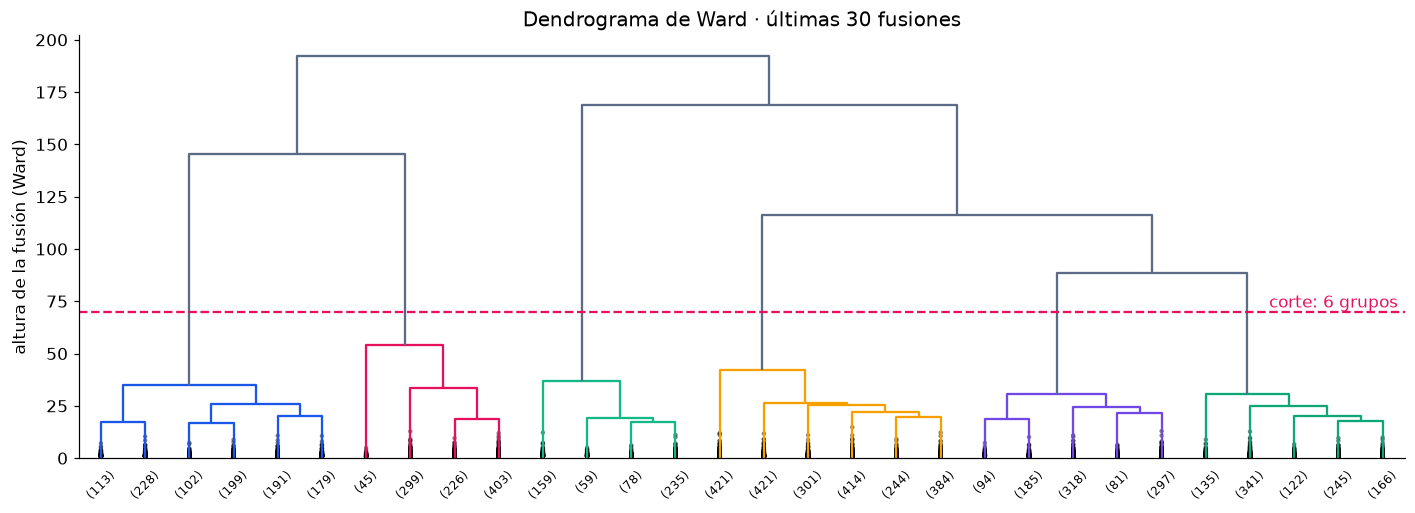

In [ ]:
# ── DEMOSTRACIÓN D.0 ──────────────────────────────────────────────────
t0 = time.time()
arbol = linkage(Zs, method="ward")
print(f"Árbol de {len(Zs)} clientes calculado en {time.time() - t0:.1f} s")

alturas = arbol[-10:, 2][::-1]          # las 10 últimas fusiones, de la más alta a la más baja
print("\nAltura de las últimas fusiones (al pasar de k + 1 a k grupos):")
for k, h in zip(range(1, 11), alturas):
    print(f"  de {k + 1:>2} a {k:>2} grupos: {h:6.1f}")

set_link_color_palette([BLUE, MAG, GREEN, "#F59F00", "#7048E8", "#0CA678"])
fig, ax = plt.subplots(figsize=(13, 4.8))
dendrogram(arbol, truncate_mode="lastp", p=30, show_contracted=True, color_threshold=70, ax=ax,
           above_threshold_color=GRAY, leaf_font_size=8)
ax.axhline(70, color=MAG, ls="--", lw=1.5)
ax.text(ax.get_xlim()[1] * 0.995, 72, "corte: 6 grupos", color=MAG, ha="right")
ax.set_ylabel("altura de la fusión (Ward)"); ax.set_title("Dendrograma de Ward · últimas 30 fusiones")
ax.grid(False)
plt.tight_layout(); plt.show()

Lee las alturas de abajo hacia arriba. Las fusiones que bajan de 11 a 7 grupos son bajas y parejas (de 33 a 42). Pasar **de 7
a 6** cuesta 54, y pasar **de 6 a 5** salta a **89**. Ese salto de 35 es el más grande de todo el árbol: unir dos de esos seis
grupos ya cuesta mucho. El dendrograma **sugiere 6 grupos sin que se lo pidamos**, el mismo número que elegimos
en la parte 1 por razones de negocio.

> Esa es la ventaja del jerárquico: **no pide k al inicio**. Se corta el árbol después, y el mismo árbol da segmentos y
> subsegmentos. La desventaja: guarda las distancias entre todos los pares de clientes, un costo que crece con $n^2$.
> Con 6 685 clientes tarda segundos; con un millón no entra en memoria.

### Ejercicio D.1 — Cuatro formas de medir la distancia entre dos grupos

Unir «los dos grupos más cercanos» obliga a decidir **qué es la distancia entre dos grupos** (el *enlace*, *linkage*):

| Enlace | Distancia entre dos grupos |
|---|---|
| `single` (simple) | la del par de clientes **más cercano** |
| `complete` (completo) | la del par **más lejano** |
| `average` (promedio) | el promedio de todos los pares |
| `ward` | cuánto **sube la varianza** dentro del grupo al unirlos |

Para cada enlace, ajusta `AgglomerativeClustering(6, linkage=enlace)` sobre `Zs` y arma `enlaces`, un DataFrame con una fila por
enlace (en el índice) y tres columnas: `ARI` (contra `y_real`, con `adjusted_rand_score`), `grupo_mayor` y `grupo_menor`
(clientes en el grupo más grande y en el más chico). Guarda las etiquetas de `ward` en `etq_ward`.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
filas = {}
for enlace in ["ward", "complete", "average", "single"]:
    etq = AgglomerativeClustering(6, linkage=enlace).fit_predict(Zs)
    tam = np.bincount(etq)
    filas[enlace] = {"ARI": adjusted_rand_score(y_real, etq), "grupo_mayor": tam.max(), "grupo_menor": tam.min()}
    if enlace == "ward":
        etq_ward = etq
enlaces = pd.DataFrame(filas).T
print(enlaces.round(3).to_string())

            ARI  grupo_mayor  grupo_menor
ward      0.956       2185.0        531.0
complete  0.495       4007.0         45.0
average   0.481       4159.0          3.0
single    0.089       6107.0          1.0


In [ ]:
# ── VERIFICACIÓN D.1 ──────────────────────────────────────────────────
def en(enlace, col):
    return None if enlaces is None or enlace not in enlaces.index else enlaces.loc[enlace, col]
r = [check("ARI de ward", en("ward", "ARI"), 0.956, tol=0.01),
     check("ARI de single", en("single", "ARI"), 0.089, tol=0.02),
     check("grupo mayor con single", en("single", "grupo_mayor"), 6107, tol=40),
     check_bool("etq_ward tiene 6 685 etiquetas", etq_ward is not None and len(etq_ward) == 6685)]
print()
print("D.1 OK" if all(r) else "Revisa D.1")

[OK] ARI de ward
     tu resultado: 0.9564   |   esperado: 0.9560
[OK] ARI de single
     tu resultado: 0.0892   |   esperado: 0.0890
[OK] grupo mayor con single
     tu resultado: 6107.0000   |   esperado: 6107.0000
[OK] etq_ward tiene 6 685 etiquetas

D.1 OK


El enlace lo cambia todo:

- **Simple** encadena: basta un par de clientes cercanos para unir dos grupos, y como los segmentos se tocan en los bordes,
  todo termina en **un grupo de más de 6 000 clientes** y varios grupos de uno. ARI 0.09.
- **Completo y promedio** quedan a mitad de camino (0.50 y 0.48): separan bien a los Dormidos y a los atípicos, pero juntan
  Cotidiano, Revolvente y Efectivo en un grupo de unos 4 000.
- **Ward** busca grupos compactos y parejos, igual que K-Means (los dos minimizan varianza), y recupera los segmentos casi
  perfecto: **0.956**, mejor que K-Means (0.923).

### Demostración D.2 — Ward contra K-Means, cliente por cliente

In [ ]:
# ── DEMOSTRACIÓN D.2 ──────────────────────────────────────────────────
if etq_ward is not None:
    seg["seg_ward"] = con_nombre(etq_ward)
    cruce = pd.crosstab(seg["seg_kmeans"], seg["seg_ward"], rownames=["K-Means"], colnames=["Ward"])
    print(cruce.to_string())
    coinciden = (seg["seg_kmeans"] == seg["seg_ward"]).mean()
    print(f"\nEl {coinciden:.1%} de los clientes cae en el mismo segmento con los dos algoritmos.")
    distintos = seg[seg["seg_kmeans"] != seg["seg_ward"]]
    print("Los cambios más comunes (K-Means → Ward):")
    print((distintos["seg_kmeans"] + " → " + distintos["seg_ward"]).value_counts().head(4).to_string())

Ward                 Cotidiano  Digital joven  Dormido  Premium viajero  Revolvente  Usuario de efectivo
K-Means                                                                                                 
Cotidiano                 2087              0        0                2          44                    0
Digital joven                4            973        0                1           0                    0
Dormido                      0              0      531                0           0                    0
Premium viajero              2              0        0             1009           0                    0
Revolvente                  92              0        0                0         915                   22
Usuario de efectivo          0              0        0                0          16                  987

El 97.3% de los clientes cae en el mismo segmento con los dos algoritmos.
Los cambios más comunes (K-Means → Ward):
Revolvente → Cotidiano              92
Coti

Los dos algoritmos coinciden en casi todos los clientes. Las diferencias están en la **frontera Cotidiano–Revolvente**: un
centenar de clientes que K-Means llama Revolvente y Ward manda a Cotidiano. Son clientes con utilización media, justo entre
los dos perfiles. Cualquier segmentación tiene una frontera así; lo importante es saber dónde está.

---
# Bloque E · Densidad: DBSCAN y HDBSCAN  ·  25 min

Los algoritmos de densidad entienden «grupo» de otra manera: **una zona donde hay muchos clientes juntos**. Lo que queda entre
zonas densas es **ruido** (etiqueta −1), y no se le fuerza ningún grupo. Esto responde la primera pregunta abierta.

DBSCAN tiene dos parámetros:

- `eps`: el radio del vecindario de cada cliente.
- `min_samples`: cuántos vecinos dentro de `eps` necesita un cliente para ser **núcleo** de un grupo.

Un cliente que está dentro del radio de un núcleo pero no tiene suficientes vecinos es **borde**. El que no es ni núcleo ni borde
es **ruido**. Regla práctica para `min_samples`: el doble del número de variables (aquí, 24).

### Demostración E.0 — Elegir `eps` con el gráfico de distancias al k-ésimo vecino

Para cada cliente se calcula la distancia a su vecino número 24 y se ordenan de menor a mayor. Donde la curva se dispara (el
«codo»), los clientes empiezan a estar lejos de todos: ese es un buen `eps`.

Distancia al vecino 24, percentiles 50 · 90 · 95 · 99: [1.38 1.81 1.95 2.29]


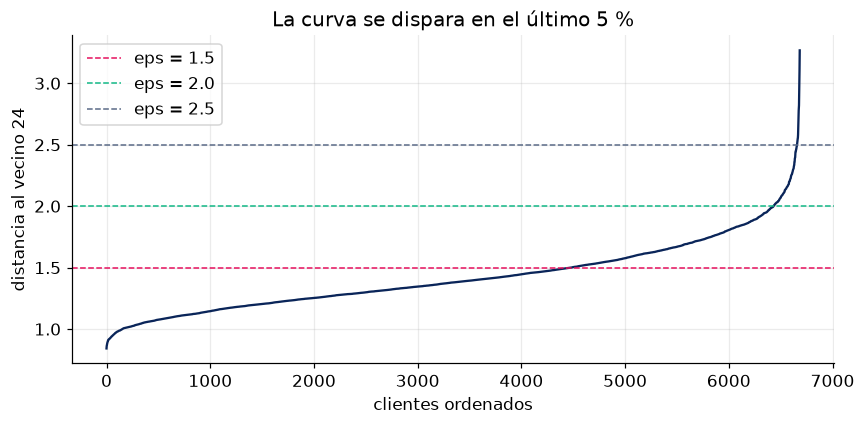

In [ ]:
# ── DEMOSTRACIÓN E.0 ──────────────────────────────────────────────────
vecinos = NearestNeighbors(n_neighbors=24).fit(Zs)
dist, _ = vecinos.kneighbors(Zs)
d24 = np.sort(dist[:, -1])
print("Distancia al vecino 24, percentiles 50 · 90 · 95 · 99:", np.percentile(d24, [50, 90, 95, 99]).round(2))

plt.figure(figsize=(8, 4))
plt.plot(d24, color=NAVY)
for eps, color in [(1.5, MAG), (2.0, GREEN), (2.5, GRAY)]:
    plt.axhline(eps, color=color, ls="--", lw=1, label=f"eps = {eps}")
plt.xlabel("clientes ordenados"); plt.ylabel("distancia al vecino 24")
plt.title("La curva se dispara en el último 5 %"); plt.legend()
plt.tight_layout(); plt.show()

La mitad de los clientes tiene a su vecino 24 a menos de 1.4; el 95 %, a menos de 1.95. El codo está entre **1.5 y 2.5**.

### Ejercicio E.1 — DBSCAN con tres radios

Para `eps` en `[1.5, 2.0, 2.5]`, ajusta `DBSCAN(eps=eps, min_samples=24)` sobre `Zs` y arma `dbscan`, un DataFrame con una fila
por `eps` (en el índice) y las columnas `grupos` (sin contar el ruido), `ruido` (clientes con etiqueta −1) y `ARI`.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
filas = {}
for eps in [1.5, 2.0, 2.5]:
    etq = DBSCAN(eps=eps, min_samples=24).fit_predict(Zs)
    filas[eps] = {"grupos": len(set(etq[etq >= 0])), "ruido": int((etq == -1).sum()),
                  "ARI": adjusted_rand_score(y_real, etq)}
dbscan = pd.DataFrame(filas).T
print(dbscan.round(3).to_string())

     grupos  ruido    ARI
1.5     4.0  406.0  0.253
2.0     3.0   13.0  0.089
2.5     3.0    1.0  0.089


In [ ]:
# ── VERIFICACIÓN E.1 ──────────────────────────────────────────────────
def db(eps, col):
    return None if dbscan is None or eps not in dbscan.index else dbscan.loc[eps, col]
r = [check("grupos con eps = 1.5", db(1.5, "grupos"), 4, tol=0),
     check("ruido con eps = 1.5", db(1.5, "ruido"), 406, tol=25),
     check("grupos con eps = 2.0", db(2.0, "grupos"), 3, tol=0),
     check("ARI con eps = 2.0", db(2.0, "ARI"), 0.089, tol=0.02)]
print()
print("E.1 OK" if all(r) else "Revisa E.1")

[OK] grupos con eps = 1.5
     tu resultado: 4.0000   |   esperado: 4.0000
[OK] ruido con eps = 1.5
     tu resultado: 406.0000   |   esperado: 406.0000
[OK] grupos con eps = 2.0
     tu resultado: 3.0000   |   esperado: 3.0000
[OK] ARI con eps = 2.0
     tu resultado: 0.0892   |   esperado: 0.0890

E.1 OK


DBSCAN **no recupera los segmentos**: con `eps = 2.0` encuentra solo 3 grupos, uno de más de 6 000 clientes. La razón es la
misma de la parte 1: los segmentos **se tocan** en los bordes, y para la densidad, si hay un camino continuo de clientes
cercanos entre dos segmentos, son la misma zona. Con un radio más chico (`eps = 1.5`) aparece más ruido, pero los segmentos
siguen fundidos.

Pero mira los grupos chicos de `eps = 2.0`: uno de ellos tiene **45 clientes**. Exactamente los atípicos. Y es lógico: son
raros frente a la cartera, pero se parecen entre sí. DBSCAN encontró algo que K-Means no podía encontrar.

El problema de DBSCAN es que **un solo radio vale para toda la base**. Si hay un segmento apretado y otro disperso, no hay un
`eps` que sirva para los dos. **HDBSCAN** prueba todos los radios a la vez y se queda con los grupos más **estables**. Su
parámetro principal es `min_cluster_size`: el grupo más chico que te interesa.

### Ejercicio E.2 — HDBSCAN y los clientes que no se parecen a nadie

1. `etq_hdb`: las etiquetas de `HDBSCAN(min_cluster_size=100)` sobre `Zs`.
2. `hdb_grupos` (sin contar ruido) y `hdb_ruido` (clientes con −1).
3. `atipicos_en_ruido`: cuántos de los 45 clientes con `y_real == "Atípico"` quedaron como ruido.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
etq_hdb = HDBSCAN(min_cluster_size=100).fit_predict(Zs)
hdb_grupos = len(set(etq_hdb[etq_hdb >= 0]))
hdb_ruido = int((etq_hdb == -1).sum())
atipicos_en_ruido = int(((y_real == "Atípico") & (etq_hdb == -1)).sum())
print(f"HDBSCAN: {hdb_grupos} grupos y {hdb_ruido} clientes como ruido")
print(f"De los 45 atípicos, {atipicos_en_ruido} quedaron como ruido")
print(f"ARI: {adjusted_rand_score(y_real, etq_hdb):.3f}\n")
print(pd.crosstab(y_real, etq_hdb, rownames=["segmento real"], colnames=["HDBSCAN"]).to_string())

HDBSCAN: 2 grupos y 110 clientes como ruido
De los 45 atípicos, 45 quedaron como ruido
ARI: 0.089

HDBSCAN              -1     0    1
segmento real                     
Atípico              45     0    0
Cotidiano             0  2169    0
Digital joven         4   926    0
Dormido              36     0  495
Premium viajero      11  1001    0
Revolvente            6   983    0
Usuario de efectivo   8  1001    0


In [ ]:
# ── VERIFICACIÓN E.2 ──────────────────────────────────────────────────
r = [check("grupos de HDBSCAN", hdb_grupos, 2, tol=0),
     check("clientes como ruido", hdb_ruido, 110, tol=15),
     check("atípicos marcados como ruido", atipicos_en_ruido, 45, tol=0)]
print()
print("E.2 OK" if all(r) else "Revisa E.2")

[OK] grupos de HDBSCAN
     tu resultado: 2.0000   |   esperado: 2.0000
[OK] clientes como ruido
     tu resultado: 110.0000   |   esperado: 110.0000
[OK] atípicos marcados como ruido
     tu resultado: 45.0000   |   esperado: 45.0000

E.2 OK


Como segmentación, HDBSCAN es mala (ARI 0.09): encuentra **dos** grupos, los Dormidos y todos los demás. Como **detector de
anomalías** es excelente: los **45 atípicos quedaron como ruido, sin excepción**, junto con 65 clientes más que están en los
bordes de sus segmentos. De 6 685 clientes, apartó 110 para revisar, y entre ellos están todos los raros.

### Demostración E.3 — ¿Quiénes son los que no se parecen a nadie?

In [ ]:
# ── DEMOSTRACIÓN E.3 ──────────────────────────────────────────────────
if etq_hdb is not None:
    ruido = etq_hdb == -1
    comparacion = pd.DataFrame({"resto (mediana)": seg.loc[~ruido, VARS].median(),
                                "ruido (mediana)": seg.loc[ruido, VARS].median(),
                                "45 atípicos (mediana)": seg.loc[y_real == "Atípico", VARS].median()})
    print(comparacion.round(2).to_string())
    print(f"\nTasa de default · resto: {seg.loc[~ruido, 'default_3m'].mean():.1%} · ruido: {seg.loc[ruido, 'default_3m'].mean():.1%} "
          f"· 45 atípicos: {seg.loc[y_real == 'Atípico', 'default_3m'].mean():.1%}")

                       resto (mediana)  ruido (mediana)  45 atípicos (mediana)
gasto_mensual_prom             1073.00          2473.00               21757.00
num_transacciones_mes            22.00            24.00                 174.00
ticket_promedio                  59.10           101.10                 128.00
pct_supermercado                  0.33             0.12                   0.02
pct_restaurantes                  0.16             0.08                   0.01
pct_viajes                        0.02             0.02                   0.01
pct_online                        0.16             0.25                   0.88
utilizacion_prom                  0.43             0.51                   0.46
pct_pago_saldo                    0.54             0.25                   0.12
num_avances_6m                    0.00             2.00                  14.00
pct_operaciones_app               0.39             0.55                   0.96
meses_sin_uso_6m                  0.00             0

Los 45 atípicos gastan **más de S/ 20 000 al mes** con más de 150 compras, casi todo **online**, por la app, con **avances de
efectivo** y pagando muy poco del saldo. Y sin embargo **no tienen más default** que la cartera.

No son clientes riesgosos en el sentido de la Clase 9: son clientes **raros**. En un banco, ese patrón (mucho gasto online de
golpe, avances, pago mínimo) es el que mira **prevención de fraude**, no cobranza. Por eso la densidad es útil aunque segmente
mal: se usa **antes** del clustering, para apartar a los raros y que no deformen los centros, o **después**, como alerta.

> **OPTICS**, el otro algoritmo de densidad de la clase, ordena a los clientes por qué tan accesibles son desde zonas densas
> y muestra los grupos como valles en un gráfico de alcanzabilidad. Hace lo mismo que HDBSCAN con más trabajo manual, así que
> en la práctica se usa menos. Está en `sklearn.cluster.OPTICS`.

---
# Bloque F · Mezclas gaussianas (GMM)  ·  20 min

Un **modelo de mezcla gaussiana** supone que cada segmento es una «campana» (una distribución normal multivariada) y que la
cartera es la mezcla de esas campanas. Lo ajusta con el algoritmo **EM**, que alterna dos pasos muy parecidos a los de K-Means:

1. **E:** calcula, para cada cliente, la **probabilidad** de pertenecer a cada campana.
2. **M:** mueve cada campana (su media y su covarianza) con esos pesos.

La gran diferencia con K-Means es la **pertenencia suave**: un cliente puede ser 70 % Revolvente y 30 % Cotidiano. K-Means es
el caso particular de campanas redondas, del mismo tamaño y pertenencia dura.

El parámetro clave es `covariance_type`, la forma que se le permite a cada campana:

| `covariance_type` | Forma de las campanas |
|---|---|
| `spherical` | redondas, cada una de su tamaño |
| `diag` | elipses alineadas con los ejes |
| `tied` | **todas con la misma** elipse, en cualquier orientación |
| `full` | cada una con su propia elipse: la más flexible, con más parámetros |

Para comparar modelos con distinto número de parámetros se usa el **BIC**: premia el ajuste y castiga los parámetros.
Más bajo, mejor.

### Ejercicio F.1 — ¿Qué forma de campana?

Para cada `covariance_type`, ajusta `GaussianMixture(6, covariance_type=..., n_init=3, random_state=SEED)` sobre `Zs` y arma
`covs` con una fila por tipo y las columnas `ARI` (de `.predict(Zs)` contra `y_real`) y `BIC` (`.bic(Zs)`). Guarda el modelo
`tied` en `gmm`.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
filas = {}
for tipo in ["spherical", "diag", "tied", "full"]:
    modelo = GaussianMixture(6, covariance_type=tipo, n_init=3, random_state=SEED).fit(Zs)
    filas[tipo] = {"ARI": adjusted_rand_score(y_real, modelo.predict(Zs)), "BIC": modelo.bic(Zs)}
    if tipo == "tied":
        gmm = modelo
covs = pd.DataFrame(filas).T
print(covs.round(3).to_string())

             ARI         BIC
spherical  0.922  159460.455
diag       0.827  133084.137
tied       0.967  107289.176
full       0.352   26174.495


In [ ]:
# ── VERIFICACIÓN F.1 ──────────────────────────────────────────────────
def cv(tipo, col):
    return None if covs is None or tipo not in covs.index else covs.loc[tipo, col]
r = [check("ARI con tied", cv("tied", "ARI"), 0.967, tol=0.015),
     check("ARI con full", cv("full", "ARI"), 0.352, tol=0.08),
     check_bool("full tiene el BIC más bajo", covs is not None and covs["BIC"].idxmin() == "full"),
     check_bool("gmm es el modelo tied", gmm is not None and gmm.covariance_type == "tied")]
print()
print("F.1 OK" if all(r) else "Revisa F.1")

[OK] ARI con tied
     tu resultado: 0.9670   |   esperado: 0.9670
[OK] ARI con full
     tu resultado: 0.3522   |   esperado: 0.3520
[OK] full tiene el BIC más bajo
[OK] gmm es el modelo tied

F.1 OK


Este resultado es de los más útiles del curso:

- **`tied` es el mejor algoritmo de toda la clase** (ARI 0.967). Todos los segmentos tienen una forma parecida, inclinada
  (por ejemplo, más utilización va con menos pago), y `tied` aprende esa inclinación una sola vez.
- **`full` es el peor de los cuatro** (0.35), y aun así tiene **el BIC más bajo**. Con 6 campanas libres hay más de 500
  parámetros. Las variables discretas (`meses_sin_uso_6m`, los avances) tienen muchos clientes en exactamente el mismo valor,
  y una campana `full` puede «sentarse» encima de esos valores repetidos con una varianza diminuta. El ajuste estadístico
  mejora; los segmentos de negocio desaparecen.

> **Más flexible no es mejor**, y una métrica de ajuste (el BIC, la inercia, la silueta) no sabe qué es un segmento útil.

### Demostración F.2 — El BIC para elegir k

3    126062.0
4    117743.0
5    111282.0
6    107289.0
7    105615.0
8     97416.0
9     99612.0


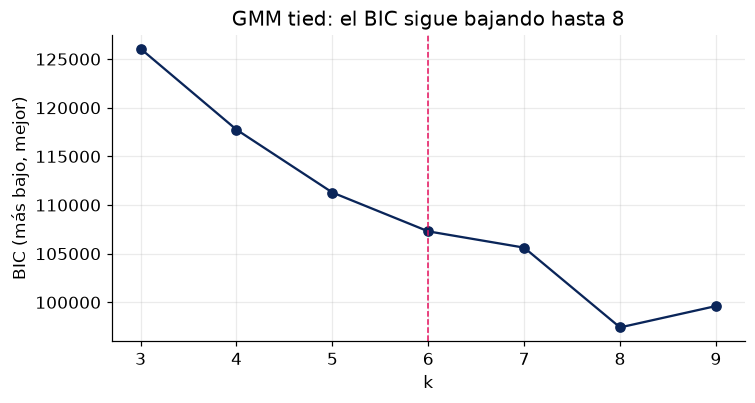

In [ ]:
# ── DEMOSTRACIÓN F.2 ──────────────────────────────────────────────────
bic_k = pd.Series({k: GaussianMixture(k, covariance_type="tied", n_init=3, random_state=SEED).fit(Zs).bic(Zs)
                   for k in range(3, 10)})
print(bic_k.round(0).to_string())
plt.figure(figsize=(7, 3.8))
plt.plot(bic_k.index, bic_k.values, "o-", color=NAVY)
plt.axvline(6, color=MAG, ls="--", lw=1)
plt.xlabel("k"); plt.ylabel("BIC (más bajo, mejor)"); plt.title("GMM tied: el BIC sigue bajando hasta 8")
plt.tight_layout(); plt.show()

El BIC baja hasta **k = 8**. Con 8 campanas, GMM parte en dos a algún segmento grande (Cotidiano tiene más de 2 000
clientes). Es la misma historia de la silueta en la parte 1, pero al revés: aquella pedía menos grupos, el BIC pide más.
**Las métricas proponen un rango; el perfil y la acción eligen.**

### Ejercicio F.3 — La pertenencia con probabilidad

1. `proba`: la matriz `gmm.predict_proba(Zs)` (una fila por cliente, una columna por campana).
2. `p_max`: la probabilidad más alta de cada cliente.
3. `pct_dudosos`: la proporción de clientes con `p_max < 0.9`.
4. `fronteras`: para los dudosos, cuántos hay en cada **par de segmentos** (los dos de mayor probabilidad), de mayor a menor.
   La celda ya trae `nombres_gmm`, el nombre de cada campana.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
etq_gmm = gmm.predict(Zs)
mapa_gmm = nombrar(seg.groupby(etq_gmm)[VARS].mean())
nombres_gmm = [mapa_gmm[i] for i in range(6)]

proba = gmm.predict_proba(Zs)
p_max = proba.max(axis=1)
pct_dudosos = float((p_max < 0.9).mean())
P = pd.DataFrame(proba, columns=nombres_gmm)
dos_mayores = P[p_max < 0.9].apply(lambda fila: " – ".join(sorted(fila.nlargest(2).index)), axis=1)
fronteras = dos_mayores.value_counts()
print(f"Clientes con menos de 90 % en su segmento: {pct_dudosos:.1%}\n")
print(fronteras.to_string())

Clientes con menos de 90 % en su segmento: 2.3%

Cotidiano – Revolvente              111
Revolvente – Usuario de efectivo     34
Cotidiano – Premium viajero           5
Digital joven – Premium viajero       1


In [ ]:
# ── VERIFICACIÓN F.3 ──────────────────────────────────────────────────
r = [check("proporción de clientes dudosos", pct_dudosos, 0.0226, tol=0.01),
     check_bool("la frontera más común es Cotidiano – Revolvente",
                fronteras is not None and len(fronteras) > 0 and fronteras.index[0] == "Cotidiano – Revolvente")]
print()
print("F.3 OK" if all(r) else "Revisa F.3")
if p_max is not None:
    i = int(np.flatnonzero((p_max > 0.6) & (p_max < 0.75))[0])
    print(f"\nEjemplo, cliente {seg[ID].iloc[i]}: " +
          ", ".join(f"{n} {p:.0%}" for n, p in sorted(zip(nombres_gmm, proba[i]), key=lambda x: -x[1])[:2]))

[OK] proporción de clientes dudosos
     tu resultado: 0.0226   |   esperado: 0.0226
[OK] la frontera más común es Cotidiano – Revolvente

F.3 OK

Ejemplo, cliente 100661: Usuario de efectivo 75%, Revolvente 25%


GMM está muy seguro de casi todos: solo el **2.3 %** de los clientes tiene menos de 90 % de probabilidad en su segmento. Y los
dudosos están **donde ya sabíamos**: la frontera **Cotidiano – Revolvente**, la misma donde discrepaban Ward y K-Means, y
después la de Revolvente – Usuario de efectivo.

Para el negocio, esa probabilidad sirve: a un cliente 60 % Cotidiano y 40 % Revolvente quizás no le mandas la campaña de
compras de supermercado sin antes mirar su utilización. **K-Means no te da esa información; GMM sí.**

---
# Bloque G · Otros algoritmos, comparar y usar  ·  35 min

### Demostración G.0 — Cuatro algoritmos más

- **Mini-Batch K-Means:** K-Means con lotes de clientes, para millones de filas.
- **BIRCH:** resume a los clientes en un árbol de subgrupos y agrupa el resumen. Jerárquico y escalable.
- **Espectral:** arma un **grafo** de vecinos y agrupa a los clientes bien conectados entre sí. Bueno para formas raras; caro.
- **Mean Shift:** mueve a cada cliente hacia la zona más densa cercana. No pide k, sí un ancho de banda.

Los juntamos con todo lo de hoy en el diccionario `etiquetas`.

In [ ]:
# ── DEMOSTRACIÓN G.0 ──────────────────────────────────────────────────
etiquetas = {"K-Means": km6.labels_}
if etq_ward is not None: etiquetas["Ward"] = etq_ward
if enlaces is not None:
    for enlace in ["complete", "average", "single"]:
        etiquetas[f"Jerárquico {enlace}"] = AgglomerativeClustering(6, linkage=enlace).fit_predict(Zs)
if etq_hdb is not None: etiquetas["HDBSCAN"] = etq_hdb
etiquetas["DBSCAN eps 2.0"] = DBSCAN(eps=2.0, min_samples=24).fit_predict(Zs)
if gmm is not None: etiquetas["GMM tied"] = gmm.predict(Zs)

tiempos = {}
otros = {
    "Mini-Batch K-Means": lambda: MiniBatchKMeans(6, n_init=10, batch_size=1024, random_state=SEED).fit_predict(Zs),
    "BIRCH": lambda: Birch(n_clusters=6, threshold=0.8).fit_predict(Zs),
    "Espectral": lambda: SpectralClustering(6, affinity="nearest_neighbors", n_neighbors=15, assign_labels="cluster_qr",
                                            random_state=SEED).fit_predict(Zs),
    "Mean Shift": lambda: MeanShift(bandwidth=estimate_bandwidth(Zs, quantile=0.1, n_samples=1500, random_state=SEED),
                                    bin_seeding=True).fit_predict(Zs),
}
for nombre, ajustar in otros.items():
    t0 = time.time()
    etiquetas[nombre] = ajustar()
    tiempos[nombre] = time.time() - t0
    print(f"{nombre:20s} {time.time() - t0:5.1f} s · {len(set(etiquetas[nombre]))} grupos")

Mini-Batch K-Means     0.0 s · 6 grupos
BIRCH                  0.1 s · 6 grupos
Espectral              0.8 s · 6 grupos
Mean Shift             0.7 s · 5 grupos


### Ejercicio G.1 — La tabla para elegir algoritmo

Completa `comparar(etiquetas)`: para cada algoritmo devuelve una fila con

- `grupos`: grupos sin contar el ruido; `ruido`: clientes con −1.
- `ARI` y `NMI` contra `y_real` (`normalized_mutual_info_score`, otra métrica externa que va de 0 a 1).
- `silueta`: `silhouette_score` **solo sobre los clientes que no son ruido**, y solo si quedan al menos 2 grupos
  (si no, `np.nan`).

Ordena la tabla de mayor a menor `ARI`.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
def comparar(etiquetas):
    filas = {}
    for nombre, etq in etiquetas.items():
        etq = np.asarray(etq)
        validos = etq >= 0
        n_grupos = len(set(etq[validos]))
        filas[nombre] = {
            "grupos": n_grupos,
            "ruido": int((~validos).sum()),
            "ARI": adjusted_rand_score(y_real, etq),
            "NMI": normalized_mutual_info_score(y_real, etq),
            "silueta": silhouette_score(Zs[validos], etq[validos]) if n_grupos >= 2 else np.nan,
        }
    return (pd.DataFrame(filas).T.astype({"grupos": int, "ruido": int, "ARI": float, "NMI": float, "silueta": float})
            .sort_values("ARI", ascending=False))

tabla = comparar(etiquetas)
print(tabla.round(3).to_string())

                     grupos  ruido    ARI    NMI  silueta
GMM tied                  6      0  0.967  0.959    0.330
Ward                      6      0  0.956  0.948    0.329
BIRCH                     6      0  0.956  0.948    0.327
K-Means                   6      0  0.923  0.921    0.335
Espectral                 6      0  0.742  0.874    0.347
Mini-Batch K-Means        6      0  0.712  0.820    0.288
Jerárquico complete       6      0  0.495  0.756    0.270
Mean Shift                5      0  0.482  0.767    0.381
Jerárquico average        6      0  0.481  0.765    0.346
Jerárquico single         6      0  0.089  0.310    0.189
DBSCAN eps 2.0            3     13  0.089  0.308    0.365
HDBSCAN                   2    110  0.089  0.291    0.386


[OK] ARI de K-Means
     tu resultado: 0.9228   |   esperado: 0.9230
[OK] ARI de BIRCH
     tu resultado: 0.9563   |   esperado: 0.9560
[OK] ARI de Espectral
     tu resultado: 0.7420   |   esperado: 0.7420
[OK] la tabla está ordenada por ARI
[OK] el primero es GMM tied

G.1 OK


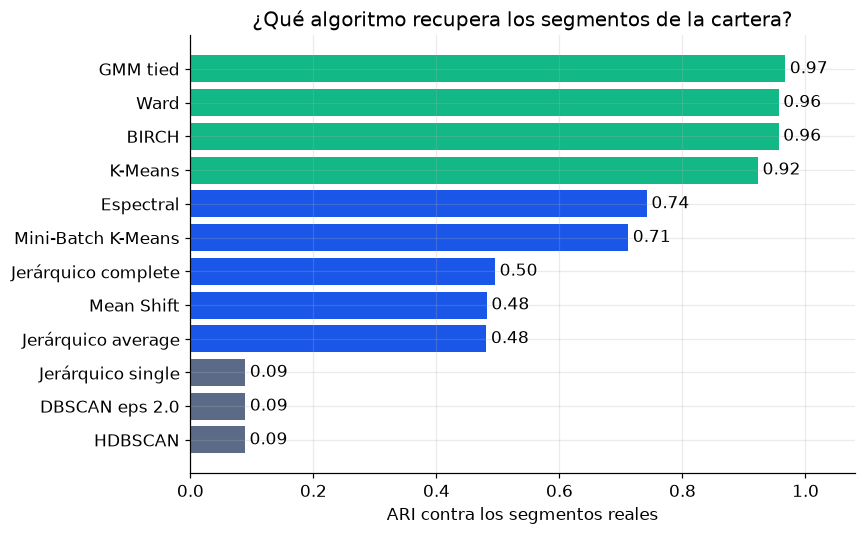

In [ ]:
# ── VERIFICACIÓN G.1 ──────────────────────────────────────────────────
def tb(nombre, col):
    return None if tabla is None or nombre not in tabla.index else tabla.loc[nombre, col]
r = [check("ARI de K-Means", tb("K-Means", "ARI"), 0.923, tol=0.01),
     check("ARI de BIRCH", tb("BIRCH", "ARI"), 0.956, tol=0.015),
     check("ARI de Espectral", tb("Espectral", "ARI"), 0.742, tol=0.05),
     check_bool("la tabla está ordenada por ARI", tabla is not None and tabla["ARI"].is_monotonic_decreasing),
     check_bool("el primero es GMM tied", tabla is not None and tabla.index[0] == "GMM tied")]
print()
print("G.1 OK" if all(r) else "Revisa G.1")
if tabla is not None:
    s = tabla["ARI"].astype(float).sort_values()
    plt.figure(figsize=(8, 5))
    barras = plt.barh(s.index, s.values, color=[GREEN if v > 0.9 else BLUE if v > 0.4 else GRAY for v in s.values])
    plt.bar_label(barras, labels=[f"{v:.2f}" for v in s.values], padding=3)
    plt.xlim(0, 1.08); plt.xlabel("ARI contra los segmentos reales")
    plt.title("¿Qué algoritmo recupera los segmentos de la cartera?")
    plt.tight_layout(); plt.show()

La tabla en tres grupos:

- **Recuperan los segmentos (ARI > 0.9):** GMM `tied`, Ward, BIRCH y K-Means. Todos suponen grupos compactos de forma
  parecida, y estos segmentos lo son.
- **A medias (0.48 a 0.80):** Mini-Batch (pierde precisión por los lotes), espectral, jerárquico completo y promedio, Mean Shift.
- **Fallan como segmentación:** single, DBSCAN y HDBSCAN. Pero HDBSCAN es el único que **separó a los 45 atípicos**.

Mira también la **silueta**: no ordena igual que el ARI. **HDBSCAN tiene la silueta más alta de toda la tabla (0.39) y el
peor ARI**: dos grupos muy separados (Dormidos contra el resto) son fáciles de separar, pero no son una segmentación. Recuerda que en la vida real **no tienes el ARI**:
solo tienes las métricas internas y tu criterio de negocio.

### Demostración G.2 — Las métricas internas no se ponen de acuerdo

In [ ]:
# ── DEMOSTRACIÓN G.2 ──────────────────────────────────────────────────
internas = {}
for k in [4, 6]:
    etq = KMeans(k, n_init=10, random_state=SEED).fit_predict(Zs)
    internas[f"k = {k}"] = {"silueta (más alta mejor)": silhouette_score(Zs, etq),
                            "Davies-Bouldin (más bajo mejor)": davies_bouldin_score(Zs, etq),
                            "Calinski-Harabasz (más alto mejor)": calinski_harabasz_score(Zs, etq)}
print(pd.DataFrame(internas).round(3).to_string())

                                       k = 4     k = 6
silueta (más alta mejor)               0.378     0.335
Davies-Bouldin (más bajo mejor)        0.975     1.138
Calinski-Harabasz (más alto mejor)  2621.566  2794.443


La silueta y Davies-Bouldin prefieren **k = 4**; Calinski-Harabasz prefiere **k = 6**. Y sabemos que los segmentos reales son 6.
Las métricas internas sirven para descartar opciones malas, no para elegir solas.

Falta decidir algo que ninguna tabla responde: **¿los segmentos se pueden usar mes a mes?** Dos pruebas antes de llevar una
segmentación a producción: que sea **estable** y que se pueda **asignar a clientes nuevos**.

### Ejercicio G.3 — Estabilidad: ¿los clientes caen siempre en el mismo segmento?

Si cambias un poco la muestra y los segmentos cambian mucho, no sirven para una campaña. Haz 10 repeticiones:

1. Toma al azar el **80 %** de los clientes (`rng.choice(len(Zs), int(0.8 * len(Zs)), replace=False)`).
2. Ajusta `KMeans(6, n_init=10, random_state=rep)` solo con esa muestra.
3. Asigna a **todos** los clientes con `.predict(Zs)` y calcula el ARI contra `km6.labels_`.

Guarda los 10 valores en `estab_km`. Haz lo mismo con `GaussianMixture(6, covariance_type="tied", n_init=3, random_state=rep)`
contra `gmm.predict(Zs)` y guárdalos en `estab_gmm`.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
rng = np.random.default_rng(SEED)
ref_gmm = gmm.predict(Zs)
estab_km, estab_gmm = [], []
for rep in range(10):
    idx = rng.choice(len(Zs), int(0.8 * len(Zs)), replace=False)
    estab_km.append(adjusted_rand_score(km6.labels_, KMeans(6, n_init=10, random_state=rep).fit(Zs[idx]).predict(Zs)))
    g = GaussianMixture(6, covariance_type="tied", n_init=3, random_state=rep).fit(Zs[idx])
    estab_gmm.append(adjusted_rand_score(ref_gmm, g.predict(Zs)))
print("K-Means  :", np.round(estab_km, 3), f"· promedio {np.mean(estab_km):.3f} · mínimo {np.min(estab_km):.3f}")
print("GMM tied :", np.round(estab_gmm, 3), f"· promedio {np.mean(estab_gmm):.3f} · mínimo {np.min(estab_gmm):.3f}")

K-Means  : [0.996 0.996 0.998 0.995 0.998 0.995 0.995 0.997 0.998 0.997] · promedio 0.997 · mínimo 0.995
GMM tied : [1.    0.999 0.999 0.998 0.999 1.    0.998 0.852 1.    0.998] · promedio 0.984 · mínimo 0.852


In [ ]:
# ── VERIFICACIÓN G.3 ──────────────────────────────────────────────────
ok_km = len(estab_km) == 10
r = [check("estabilidad media de K-Means", np.mean(estab_km) if ok_km else None, 0.997, tol=0.005),
     check_bool("K-Means nunca baja de 0.99", ok_km and min(estab_km) > 0.99),
     check_bool("calculaste las 10 de GMM", len(estab_gmm) == 10)]
print()
print("G.3 OK" if all(r) else "Revisa G.3")

[OK] estabilidad media de K-Means
     tu resultado: 0.9967   |   esperado: 0.9970
[OK] K-Means nunca baja de 0.99
[OK] calculaste las 10 de GMM

G.3 OK


**K-Means es muy estable**: con cualquier 80 % de la cartera, más del 99 % de los clientes cae en el mismo segmento. GMM `tied`
tuvo el mejor ARI de la clase, pero es **menos estable**: en alguna repetición el algoritmo EM se queda en otra solución y el
ARI cae a 0.85. Con `n_init` más alto se corrige, a cambio de tiempo. Es un buen ejemplo de por qué el ganador de una tabla no
siempre es el que se lleva a producción.

### Ejercicio G.4 — ¿Cómo se asigna un cliente nuevo?

El mes que viene entran clientes nuevos. **K-Means, GMM y BIRCH tienen `.predict`**: el cliente nuevo va al centro o a la
campana más cercana. **Jerárquico, DBSCAN, HDBSCAN y espectral no**: solo etiquetan a los clientes con que se ajustaron.

La solución estándar: entrenar un **clasificador** que aprenda a reproducir los segmentos. Supongamos que el banco eligió Ward.

1. Separa `Zs` y `seg["seg_ward"]` en entrenamiento y prueba con `train_test_split(..., test_size=0.3, random_state=SEED,
   stratify=seg["seg_ward"])`.
2. Entrena `arbol_seg = DecisionTreeClassifier(max_depth=6, random_state=SEED)`.
3. `exactitud`: la proporción de clientes de prueba que el árbol asigna al mismo segmento que Ward (`.score`).

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
X_ent, X_pru, s_ent, s_pru = train_test_split(Zs, seg["seg_ward"], test_size=0.3, random_state=SEED,
                                              stratify=seg["seg_ward"])
arbol_seg = DecisionTreeClassifier(max_depth=6, random_state=SEED).fit(X_ent, s_ent)
exactitud = arbol_seg.score(X_pru, s_pru)
print(f"El árbol reproduce el segmento de Ward en el {exactitud:.1%} de los clientes de prueba")
importancia = pd.Series(arbol_seg.feature_importances_, index=VARS).sort_values(ascending=False)
print("\nVariables que más usa el árbol para asignar el segmento:")
print(importancia.head(5).round(3).to_string())

El árbol reproduce el segmento de Ward en el 97.0% de los clientes de prueba

Variables que más usa el árbol para asignar el segmento:
pct_pago_saldo        0.208
pct_supermercado      0.198
gasto_mensual_prom    0.181
num_avances_6m        0.145
meses_sin_uso_6m      0.133


In [ ]:
# ── VERIFICACIÓN G.4 ──────────────────────────────────────────────────
r = [check("exactitud del árbol", exactitud, 0.970, tol=0.015)]
print()
print("G.4 OK" if all(r) else "Revisa G.4")

[OK] exactitud del árbol
     tu resultado: 0.9696   |   esperado: 0.9700

G.4 OK


Un árbol de 6 niveles reproduce los segmentos de Ward en el **97 %** de los clientes nuevos. Y se gana algo más: el árbol es un
conjunto de **reglas** («si utilización > X y pago < Y, Revolvente») que se pueden escribir en SQL y correr en el *data
warehouse* todos los meses, sin Python. Esa es la conexión con la próxima clase: poner un modelo en producción.

---
# Bloque H · PCA: reducir dimensiones y mirar  ·  20 min

En la parte 1 usamos PCA solo para **dibujar** los segmentos en dos dimensiones. Hoy lo vemos en serio, porque aparece en
casi todo proyecto de clustering con muchas variables.

**PCA** (*análisis de componentes principales*) busca nuevas variables, las **componentes**, que cumplen tres cosas:

1. Cada componente es una **combinación lineal** de las variables originales: $PC_1 = w_1 x_1 + w_2 x_2 + \dots + w_{12} x_{12}$.
2. La primera componente es la dirección en que los clientes **más varían**; la segunda, la que más varía entre las que
   son perpendiculares a la primera, y así.
3. Las componentes **no están correlacionadas** entre sí.

Con 12 variables hay 12 componentes. Si las primeras concentran casi toda la varianza, se pueden **descartar las últimas**
perdiendo poca información. Los pesos $w$ se llaman **cargas** (*loadings*) y dicen qué significa cada componente.

> PCA se calcula con varianzas, así que **también hay que escalar antes**. Por eso lo aplicamos sobre `Zs`, no sobre los datos crudos.

### Ejercicio H.1 — ¿Cuánta varianza explica cada componente?

1. `pca`: `PCA(random_state=SEED)` ajustado sobre `Zs` (con todas las componentes).
2. `var_exp`: la proporción de varianza de cada componente (`explained_variance_ratio_`) y `var_acum`, su suma acumulada.
3. `n_80`: cuántas componentes hacen falta para llegar al **80 %** de la varianza.
4. `n_kaiser`: cuántas componentes tienen varianza (`explained_variance_`) **mayor que 1**. Es el criterio de Kaiser: con datos
   estandarizados, cada variable original aporta varianza 1, así que una componente que no supera 1 explica menos que una
   sola variable.

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
pca = PCA(random_state=SEED).fit(Zs)
var_exp = pca.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
n_80 = int(np.argmax(var_acum >= 0.80) + 1)
n_kaiser = int((pca.explained_variance_ > 1).sum())
print(pd.DataFrame({"varianza": pca.explained_variance_, "% explicado": var_exp, "% acumulado": var_acum},
                   index=[f"PC{i}" for i in range(1, 13)]).round(3).to_string())
print(f"\nPara el 80 % hacen falta {n_80} componentes · criterio de Kaiser: {n_kaiser}")

      varianza  % explicado  % acumulado
PC1      3.676        0.306        0.306
PC2      2.488        0.207        0.514
PC3      1.935        0.161        0.675
PC4      1.073        0.089        0.764
PC5      0.938        0.078        0.842
PC6      0.673        0.056        0.898
PC7      0.460        0.038        0.937
PC8      0.258        0.022        0.958
PC9      0.208        0.017        0.976
PC10     0.179        0.015        0.991
PC11     0.113        0.009        1.000
PC12     0.001        0.000        1.000

Para el 80 % hacen falta 5 componentes · criterio de Kaiser: 4


[OK] varianza explicada por PC1
     tu resultado: 0.3063   |   esperado: 0.3060
[OK] varianza acumulada con 2 componentes
     tu resultado: 0.5136   |   esperado: 0.5140
[OK] componentes para el 80 %
     tu resultado: 5.0000   |   esperado: 5.0000
[OK] componentes con varianza > 1 (Kaiser)
     tu resultado: 4.0000   |   esperado: 4.0000

H.1 OK


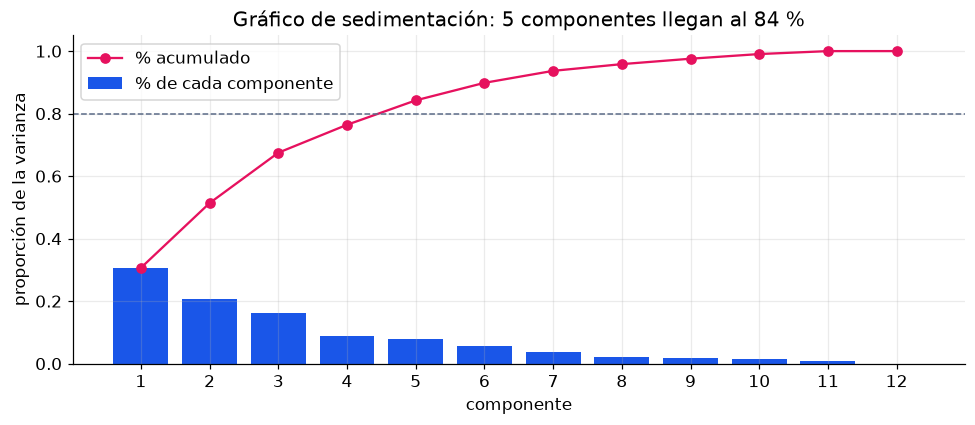

In [ ]:
# ── VERIFICACIÓN H.1 ──────────────────────────────────────────────────
r = [check("varianza explicada por PC1", None if var_exp is None else var_exp[0], 0.306, tol=0.005),
     check("varianza acumulada con 2 componentes", None if var_acum is None else var_acum[1], 0.514, tol=0.005),
     check("componentes para el 80 %", n_80, 5, tol=0),
     check("componentes con varianza > 1 (Kaiser)", n_kaiser, 4, tol=0)]
print()
print("H.1 OK" if all(r) else "Revisa H.1")
if var_exp is not None:
    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(1, 13)
    ax.bar(x, var_exp, color=BLUE, label="% de cada componente")
    ax.plot(x, var_acum, "o-", color=MAG, label="% acumulado")
    ax.axhline(0.8, color=GRAY, ls="--", lw=1)
    ax.set_xticks(x); ax.set_xlabel("componente"); ax.set_ylabel("proporción de la varianza")
    ax.set_title("Gráfico de sedimentación: 5 componentes llegan al 84 %"); ax.legend()
    plt.tight_layout(); plt.show()

Las dos primeras componentes juntan **el 51 %** de la varianza: por eso el dibujo de la parte 1 mostraba los segmentos
encimados. Con **5** se llega al 84 %, y el criterio de Kaiser se queda con **4**.

Mira la **última componente**: su varianza es prácticamente **cero**. Eso significa que una de las 12 variables es una
combinación exacta de otras. La demostración siguiente dice cuál.

### Demostración H.2 — Qué significa cada componente: las cargas

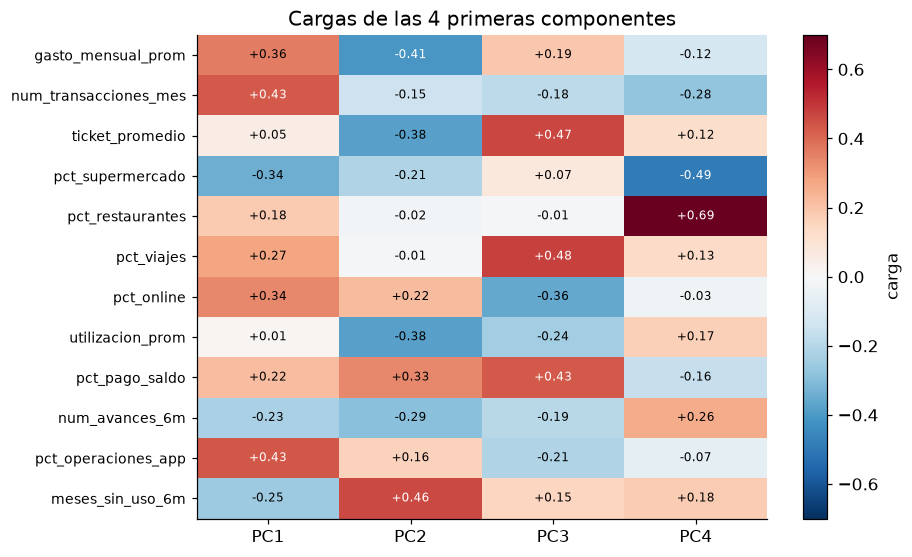

La última componente (PC12), con varianza 0.0008
gasto_mensual_prom       0.697
num_transacciones_mes   -0.520
ticket_promedio         -0.492


In [ ]:
# ── DEMOSTRACIÓN H.2 ──────────────────────────────────────────────────
if pca is not None:
    cargas = pd.DataFrame(pca.components_.T, index=VARS, columns=[f"PC{i}" for i in range(1, 13)])
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    im = ax.imshow(cargas[["PC1", "PC2", "PC3", "PC4"]].values, cmap="RdBu_r", vmin=-0.7, vmax=0.7, aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(["PC1", "PC2", "PC3", "PC4"])
    ax.set_yticks(range(len(VARS))); ax.set_yticklabels(VARS, fontsize=9)
    for (f, c), v in np.ndenumerate(cargas[["PC1", "PC2", "PC3", "PC4"]].values):
        ax.text(c, f, f"{v:+.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.4 else "black")
    ax.grid(False); plt.colorbar(im, label="carga")
    ax.set_title("Cargas de las 4 primeras componentes")
    plt.tight_layout(); plt.show()

    print("La última componente (PC12), con varianza", round(pca.explained_variance_[-1], 4))
    print(cargas["PC12"].round(3)[cargas["PC12"].abs() > 0.05].to_string())

Cómo se lee una carga: un valor alto (positivo o negativo) quiere decir que esa variable pesa mucho en la componente; el signo
dice hacia qué lado. Leyendo las columnas:

- **PC1 · uso activo y digital.** Suben las transacciones, la app, el % online y el gasto; bajan el supermercado, los meses
  sin uso y los avances. A la derecha están los Digital joven; a la izquierda, los Dormidos y los de efectivo.
- **PC2 · gastar y deber contra pagar o no usar.** Negativo: gasto, ticket y utilización altos. Positivo: meses sin uso y
  pago del saldo. Abajo quedan los Revolventes; muy arriba, los Dormidos.
- **PC3 · viajero.** Viajes, ticket y pago del saldo: es el eje de los Premium viajero.
- **PC4 · restaurantes contra supermercado.**

Las componentes **no traen nombre**: se lo pones tú leyendo las cargas, igual que a los clusters.

Y la **PC12**: gasto con +0.70, transacciones con −0.52 y ticket con −0.49. Es que `ticket_promedio` = gasto / transacciones,
y en logaritmo eso es una resta exacta: $\log(\text{ticket}) \approx \log(\text{gasto}) - \log(\text{trx})$. **El ticket no agrega
información nueva**; solo le da un tercer voto al gasto en la distancia. PCA lo detectó solo. Es un buen uso de PCA aunque no
reduzcas nada: **revisar si hay variables redundantes** antes de agrupar.

### Ejercicio H.3 — ¿Agrupar sobre las componentes?

Una práctica común es aplicar K-Means **sobre las primeras componentes** en vez de sobre las 12 variables. Pruébalo: para `m` en
`[2, 3, 4, 6, 8, 12]`, proyecta `Zs` con `PCA(m, random_state=SEED)`, ajusta `KMeans(6, n_init=10, random_state=SEED)` sobre la
proyección y arma `tabla_pca` con una fila por `m` y las columnas `var_acum` (varianza conservada), `ARI` (contra `y_real`) y
`silueta` (calculada **en el espacio reducido**).

In [ ]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
filas = {}
for m in [2, 3, 4, 6, 8, 12]:
    pca_m = PCA(m, random_state=SEED).fit(Zs)
    Pm = pca_m.transform(Zs)
    etq = KMeans(6, n_init=10, random_state=SEED).fit_predict(Pm)
    filas[m] = {"var_acum": pca_m.explained_variance_ratio_.sum(),
                "ARI": adjusted_rand_score(y_real, etq), "silueta": silhouette_score(Pm, etq)}
tabla_pca = pd.DataFrame(filas).T
tabla_pca.index.name = "componentes"
print(tabla_pca.round(3).to_string())

             var_acum    ARI  silueta
componentes                          
2               0.514  0.788    0.492
3               0.675  0.879    0.487
4               0.764  0.856    0.451
6               0.898  0.903    0.397
8               0.958  0.919    0.359
12              1.000  0.923    0.335


[OK] ARI con 2 componentes
     tu resultado: 0.7884   |   esperado: 0.7880
[OK] ARI con 6 componentes
     tu resultado: 0.9035   |   esperado: 0.9030
[OK] ARI con las 12
     tu resultado: 0.9228   |   esperado: 0.9230
[OK] la silueta con 2 componentes es mayor que con 12

H.3 OK


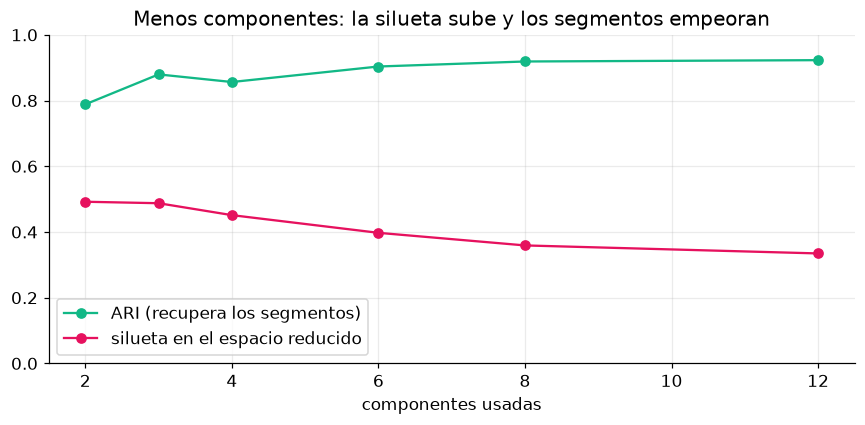

In [ ]:
# ── VERIFICACIÓN H.3 ──────────────────────────────────────────────────
def tp(m, col):
    return None if tabla_pca is None or m not in tabla_pca.index else tabla_pca.loc[m, col]
r = [check("ARI con 2 componentes", tp(2, "ARI"), 0.788, tol=0.02),
     check("ARI con 6 componentes", tp(6, "ARI"), 0.903, tol=0.02),
     check("ARI con las 12", tp(12, "ARI"), 0.923, tol=0.01),
     check_bool("la silueta con 2 componentes es mayor que con 12", tp(2, "silueta") is not None and tp(2, "silueta") > tp(12, "silueta"))]
print()
print("H.3 OK" if all(r) else "Revisa H.3")
if tabla_pca is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(tabla_pca.index, tabla_pca["ARI"], "o-", color=GREEN, label="ARI (recupera los segmentos)")
    ax.plot(tabla_pca.index, tabla_pca["silueta"], "o-", color=MAG, label="silueta en el espacio reducido")
    ax.set_xlabel("componentes usadas"); ax.set_ylim(0, 1); ax.legend()
    ax.set_title("Menos componentes: la silueta sube y los segmentos empeoran")
    plt.tight_layout(); plt.show()

Dos lecciones en un gráfico:

- **Reducir cuesta.** Con 2 componentes el ARI cae a 0.79; con 6 (el 90 % de la varianza) ya está en 0.90, cerca de las 12
  variables (0.92). Aquí no hay mucho que ganar: 12 variables no son muchas. PCA antes del clustering conviene cuando hay
  **decenas o cientos** de variables correlacionadas, o mucho ruido.
- **La silueta engaña otra vez.** En 2 dimensiones la silueta sube a 0.49, la más alta de toda la clase, porque los grupos se
  ven más separados en un espacio más chico. Pero esos grupos son **peores**. **Nunca compares siluetas calculadas en espacios
  distintos.**

### Demostración H.4 — El mapa de la cartera: segmentos, atípicos y cargas

El uso que nunca falla: PCA para **mirar**. Proyectamos en PC1 y PC2, coloreamos por segmento, marcamos el ruido de HDBSCAN y
dibujamos las flechas de las cargas de algunas variables (un *biplot*).

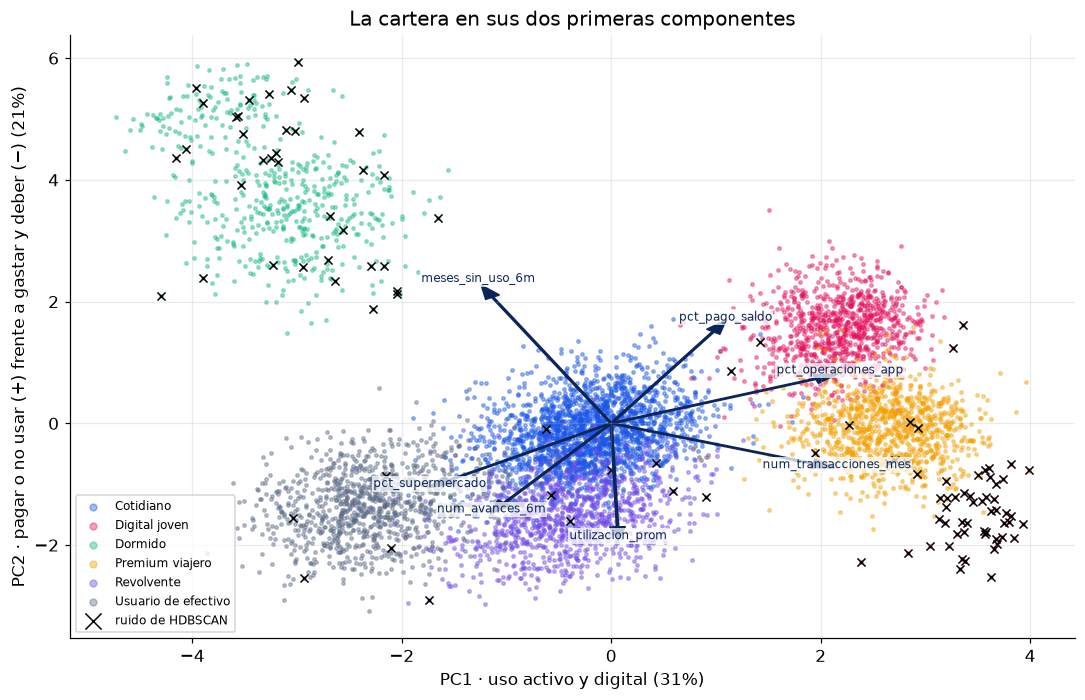

In [ ]:
# ── DEMOSTRACIÓN H.4 ──────────────────────────────────────────────────
if pca is not None:
    P2 = pca.transform(Zs)[:, :2]
    fig, ax = plt.subplots(figsize=(10, 6.5))
    for color, (nombre, idx) in zip(COLORES, seg.groupby("seg_kmeans").groups.items()):
        ax.scatter(P2[idx, 0], P2[idx, 1], s=5, alpha=0.4, color=color, label=nombre)
    if etq_hdb is not None:
        ruido = etq_hdb == -1
        ax.scatter(P2[ruido, 0], P2[ruido, 1], s=28, marker="x", color="black", lw=1, label="ruido de HDBSCAN")
    escala = 4.5
    for var in ["num_transacciones_mes", "pct_operaciones_app", "meses_sin_uso_6m", "utilizacion_prom",
                "pct_pago_saldo", "num_avances_6m", "pct_supermercado"]:
        j = VARS.index(var)
        ax.arrow(0, 0, escala * pca.components_[0, j], escala * pca.components_[1, j], color=NAVY, width=0.02, head_width=0.15)
        ax.text(escala * 1.12 * pca.components_[0, j], escala * 1.12 * pca.components_[1, j], var, fontsize=8, color=NAVY,
                ha="center", bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1))
    ax.set_xlabel(f"PC1 · uso activo y digital ({var_exp[0]:.0%})")
    ax.set_ylabel(f"PC2 · pagar o no usar (+) frente a gastar y deber (−) ({var_exp[1]:.0%})")
    ax.set_title("La cartera en sus dos primeras componentes"); ax.legend(markerscale=2, fontsize=8, loc="lower left")
    plt.tight_layout(); plt.show()

El *biplot* junta en un dibujo lo que vimos por separado: los Dormidos arriba, hacia `meses_sin_uso_6m`; los Digital joven a la
derecha, hacia la app y las transacciones; los Usuarios de efectivo hacia los avances; los Revolventes abajo, hacia la
utilización. Y las **x negras** del ruido de HDBSCAN: un grupo apretado abajo a la derecha, más allá de los Digital joven (los
45 atípicos), y otras sueltas en los bordes de los segmentos, sobre todo entre los Dormidos.

> **t-SNE y UMAP** hacen mapas en 2D que separan mucho mejor los grupos, porque no son lineales. Pero deforman las distancias:
> sirven **solo para mirar**, nunca para agrupar encima ni para leer cuánto se parecen dos grupos. PCA es lineal, se puede
> explicar con sus cargas y tiene `transform` para clientes nuevos.

---
# Cierre

### Los números del día

| | |
|---|---|
| Dendrograma (Ward) | el salto más grande del árbol está de 6 a 5 grupos: sugiere k = 6 solo |
| Tipo de enlace | ARI de 0.09 (single) a 0.96 (Ward), con los mismos datos |
| DBSCAN / HDBSCAN | segmentan mal (ARI 0.09), pero HDBSCAN marca como ruido a los **45 de 45** atípicos |
| GMM | `tied` es el mejor de la clase (0.967); `full` el peor (0.35) con el mejor BIC |
| Dudosos de GMM | 2.3 % de los clientes, casi todos en la frontera Cotidiano – Revolvente |
| Estabilidad | K-Means 0.997 con muestras del 80 %; GMM menos estable |
| Asignar nuevos | un árbol de 6 niveles reproduce los segmentos de Ward en el 97 % |
| PCA | 2 componentes explican el 51 %, 5 el 84 %; la PC12 tiene varianza cero: el ticket es gasto / transacciones |
| K-Means sobre PCA | ARI 0.79 con 2 componentes, 0.90 con 6 y 0.92 con las 12; la silueta engaña en espacios chicos |

### Checklist de salida

- [ ] Leo un **dendrograma** y sé dónde cortarlo.
- [ ] Explico los cuatro **tipos de enlace** y por qué *single* encadena.
- [ ] Explico **núcleo, borde y ruido** en DBSCAN, elijo `eps` con el gráfico del vecino k, y sé qué agrega HDBSCAN.
- [ ] Uso la densidad como **detector de anomalías** aunque no sirva para segmentar.
- [ ] Explico la **pertenencia suave** de GMM, el `covariance_type` y por qué el mejor BIC no es el mejor segmento.
- [ ] Comparo algoritmos con métricas **externas** (ARI, NMI) e **internas** (silueta, Davies-Bouldin, Calinski-Harabasz).
- [ ] Pruebo la **estabilidad** de una segmentación y sé cómo **asignar clientes nuevos** cuando el algoritmo no tiene `predict`.
- [ ] Interpreto la **varianza explicada** y las **cargas** de PCA, y sé cuándo conviene agrupar sobre componentes.

### Preguntas tipo examen

**1.** Un analista corre el jerárquico con enlace *single* y obtiene un grupo de 6 107 clientes y cuatro grupos de 1 a 45. ¿Qué pasó?

> **Respuesta.** El enlace simple une dos grupos si **un solo par** de clientes está cerca. Como los segmentos se tocan en los
> bordes, se encadenan en un grupo gigante. Para segmentar clientes se usa Ward (o completo/promedio).

**2.** HDBSCAN tiene un ARI de 0.09 en esta cartera. ¿Lo descartas?

> **Respuesta.** Para segmentar, sí. Pero marcó como ruido a los 45 clientes atípicos sin excepción: es un muy buen
> **detector de anomalías**. Se usa antes del clustering (para que los raros no deformen los centros) o como alerta.

**3.** GMM con `covariance_type="full"` tiene un BIC más bajo que con `"tied"`. ¿Te quedas con `full`?

> **Respuesta.** No necesariamente. El BIC mide ajuste estadístico. Con `full` hay cientos de parámetros y las campanas se
> acomodan a valores repetidos de variables discretas: el ARI cae a 0.35 y los segmentos no se reconocen. Hay que perfilar.

**4.** El área comercial quiere que cada cliente nuevo reciba su segmento todos los meses, y elegiste el jerárquico de Ward. ¿Cómo lo haces?

> **Respuesta.** El jerárquico no tiene `predict`. Se entrena un **clasificador** (un árbol, por ejemplo) con las variables y
> el segmento de Ward como target, y ese clasificador asigna a los nuevos. Aquí acierta el 97 %, y sus reglas se pueden
> llevar a SQL.

**5.** ¿Por qué medimos la estabilidad si ya tenemos el ARI?

> **Respuesta.** Porque en la vida real **no hay ARI** (no existe la etiqueta verdadera), y porque un segmento que cambia con
> la muestra o con el mes no sirve para una campaña. La estabilidad se puede medir siempre.

**6.** Un compañero agrupa sobre 2 componentes de PCA y reporta una silueta de 0.49, mejor que el 0.335 de K-Means con las 12 variables. ¿Su segmentación es mejor?

> **Respuesta.** No se puede saber así: las siluetas se calcularon en **espacios distintos**, y en 2 dimensiones los grupos
> siempre parecen más separados. Con 2 componentes se pierde casi la mitad de la varianza y aquí el ARI cae de 0.92 a 0.79.

### Lo que sigue

**Clase 12 · Un modelo en producción.** Tomamos un modelo entrenado, lo guardamos, lo exponemos en una aplicación web y
vemos una introducción a **Databricks**.